# Triton Requirements Guide: how it compares

Eleven UCSD requirement questions, answered by NotebookLM, by our app (Gemini API + our own catalog index), and (to be filled in) by Google AI Studio.

**Rubric** (scored against the catalog pages, not against each other)

| Score | Meaning |
|---|---|
| 2 | Correct and complete |
| 1 | Partial or missing a piece |
| 0 | Wrong, or says "not covered" when the catalog pages do cover it |

Plus: does the citation point to the right page (yes / no)? The scores are in `eval/grades.json` so anyone can check or change them.

In [1]:
import json, re
from pathlib import Path
from collections import Counter
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = Path("..") if Path("../eval").exists() else Path(".")
sys.path.insert(0, str(root))
questions = json.loads((root / "eval/questions.json").read_text())
theirs = json.loads((root / "eval/notebooklm_answers.json").read_text())
ours = json.loads((root / "eval/our_answers.json").read_text())
grades = json.loads((root / "eval/grades.json").read_text())
studio = json.loads((root / "eval/aistudio_answers.json").read_text())
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
NAVY, GREY, GOLD = "#182B49", "#9AA3B2", "#C69214"

# Our citation check is automatic: did the answer cite one of the pages that should be cited?
def our_citation(i):
    accepted = questions[i]["accept_url_substrings"]
    return any(any(a in url for a in accepted) for url in ours[i]["sources"])
for i, g in enumerate(grades["ours"]):
    g["citation"] = our_citation(i)

## 1. Scores per question

,question,NotebookLM,Ours
1,How many upper-division electives do I need fo...,0,1
2,What are the Warren College writing requirements?,1,2
3,What is the Revelle College Humanities sequence?,1,2
4,What are the general education requirements at...,2,2
5,What are the required courses for the bioengin...,0,2
6,What does CSE 150A cover?,0,2
7,How many units do I need to graduate from UCSD?,2,2
8,What math courses does a mechanical engineerin...,1,2
9,I took CSE 12 and 21. What should I take next ...,1,2
10,What are the requirements for the bioinformati...,1,2


Total out of 22:  NotebookLM 10,  Ours 21


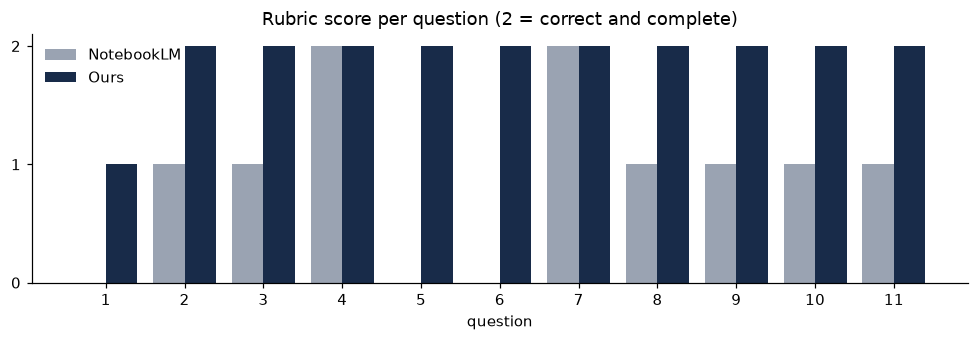

In [2]:
rows = []
for i, q in enumerate(questions):
    rows.append({"question": q["question"][:62],
                 "NotebookLM": grades["notebooklm"][i]["score"],
                 "Ours": grades["ours"][i]["score"]})
scores = pd.DataFrame(rows); scores.index += 1
display(scores)
total = scores[["NotebookLM", "Ours"]].sum()
print(f"Total out of {2 * len(scores)}:  NotebookLM {total['NotebookLM']},  Ours {total['Ours']}")

fig, ax = plt.subplots(figsize=(9, 3.2))
x = range(len(scores))
ax.bar([i - 0.2 for i in x], scores["NotebookLM"], 0.4, label="NotebookLM", color=GREY)
ax.bar([i + 0.2 for i in x], scores["Ours"], 0.4, label="Ours", color=NAVY)
ax.set_xticks(list(x)); ax.set_xticklabels(scores.index); ax.set_xlabel("question"); ax.set_yticks([0, 1, 2])
ax.set_title("Rubric score per question (2 = correct and complete)"); ax.legend(frameon=False)
plt.tight_layout()

## 2. How each tool fails

,NotebookLM,Ours
no problem,2,10
partial answer,6,1
said 'not covered' but the pages cover it,3,0


Citation points to the right page:
               NotebookLM  Ours
no                      3     0
not checkable           8     0
yes                     0    11
NotebookLM answers carry citation numbers but not page names, so 'not checkable' means the pasted answer does not say which page was used.


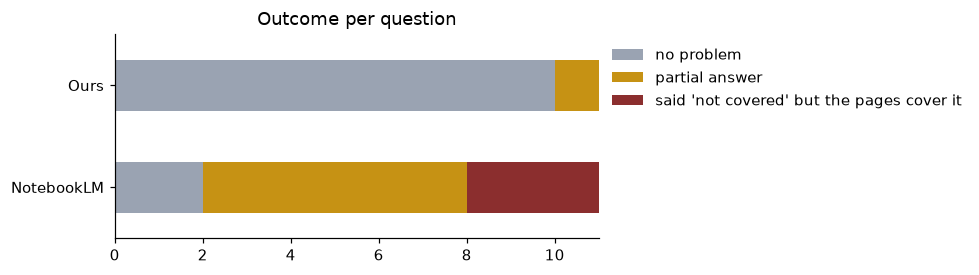

In [3]:
labels = {"none": "no problem", "incomplete": "partial answer", "not_covered": "said 'not covered' but the pages cover it"}
counts = pd.DataFrame({
    "NotebookLM": Counter(g["failure"] for g in grades["notebooklm"]),
    "Ours": Counter(g["failure"] for g in grades["ours"]),
}).fillna(0).astype(int).reindex(list(labels)).rename(index=labels)
display(counts)
counts.T.plot.barh(stacked=True, figsize=(9, 2.6), color=[GREY, GOLD, NAVY][::-1] if False else [GREY, GOLD, "#8B2E2E"])
plt.title("Outcome per question"); plt.legend(frameon=False, bbox_to_anchor=(1, 1)); plt.tight_layout()

cites = pd.DataFrame({
    "NotebookLM": [{True: "yes", False: "no", None: "not checkable"}[g["citation"]] for g in grades["notebooklm"]],
    "Ours": ["yes" if g["citation"] else "no" for g in grades["ours"]]}, index=scores.index)
print("Citation points to the right page:")
print(cites.apply(pd.Series.value_counts).fillna(0).astype(int))
print("NotebookLM answers carry citation numbers but not page names, so 'not checkable' means the pasted answer does not say which page was used.")

Reading this: NotebookLM's wrong answers are almost all the same kind, "your sources don't include this". That is a **data** problem. The answer exists in the catalog; the page was not in its sources, or it could not find the line. The next section looks at the data our app searches.

## 3. The data behind our answers

56 catalog pages  ->  1201 searchable chunks  ->  2021 courses with parsed prerequisites


,pages,chunks
major / department program,28,522
university-wide,4,110
course descriptions,17,433
college requirements,7,136


45% of courses have prerequisites the code can check (ready / missing). The rest are passed to the model as written.


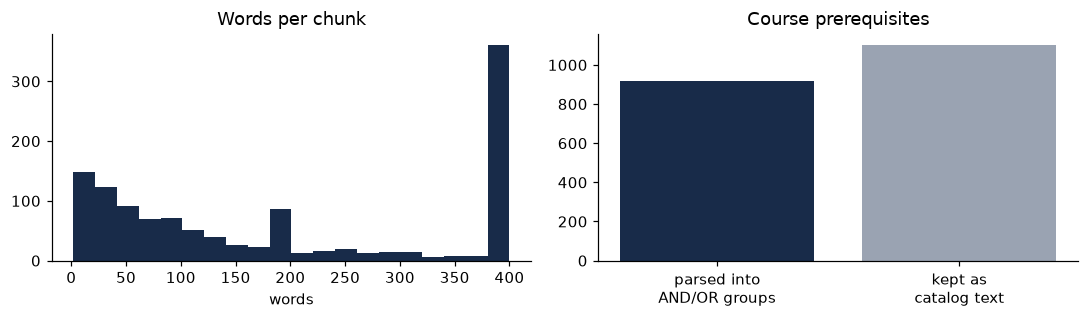

In [4]:
chunks = json.loads((root / "data/index.json").read_text())
courses = json.loads((root / "data/courses.json").read_text())
import courses as course_lookup

def kind(url):
    if "/curric/" in url: return "major / department program"
    if "/courses/" in url: return "course descriptions"
    if "/colleges/" in url: return "college requirements"
    return "university-wide"
pages = {c["url"]: kind(c["url"]) for c in chunks}
by_kind = Counter(pages.values())
print(f"{len(pages)} catalog pages  ->  {len(chunks)} searchable chunks  ->  {len(courses)} courses with parsed prerequisites")
display(pd.DataFrame({"pages": by_kind, "chunks": Counter(kind(c['url']) for c in chunks)}).fillna(0).astype(int))

words = [len(c["text"].split()) for c in chunks]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(words, bins=20, color=NAVY); axes[0].set_title("Words per chunk"); axes[0].set_xlabel("words")
structured = sum(1 for c in courses if course_lookup.prereq_groups(c) is not None)
axes[1].bar(["parsed into\nAND/OR groups", "kept as\ncatalog text"], [structured, len(courses) - structured], color=[NAVY, GREY])
axes[1].set_title("Course prerequisites")
plt.tight_layout()
print(f"{structured / len(courses):.0%} of courses have prerequisites the code can check (ready / missing). The rest are passed to the model as written.")

In [5]:
# Did retrieval put the right page in front of the model? (same check as eval/run_eval.py, from the saved run)
hit = [our_citation(i) for i in range(len(questions))]
print(f"Right page cited: {sum(hit)}/{len(hit)}")
times = [a["seconds"] for a in ours]
print(f"Answer time: median {sorted(times)[len(times)//2]} s, slowest {max(times)} s (includes retrieval)")

Right page cited: 11/11
Answer time: median 1.4 s, slowest 4.0 s (includes retrieval)


**Why the data is better than uploading the same links to a notebook tool**

- **Whole pages are indexed, not summaries.** Program pages are split by heading and each chunk starts with the program name ("BS Artificial Intelligence Program / 2. Upper-Division Requirements"), so a question about one major does not retrieve another major's rules.
- **A separate course table.** Every course has its title, units and prerequisites parsed into groups ("any one of CSE 8B, CSE 11"). That is what lets the app say CSE 12 means CSE 8B or 11 is done, and which courses are Ready or Missing. A plain document search cannot do this.
- **Retrieval is ours to tune.** "What should I take next?" searches lower-division, upper-division and elective sections separately; a named course goes to the course table first. We can test each fix with the eval, which a closed notebook tool does not allow.
- **The model is told what it may and may not do** (answer only from the sources, cite, say when something is not covered, no major-restriction noise, no courses from unrelated departments).

## 4. Google AI Studio (to be filled in)

In [6]:
def studio_table(arm):
    items = studio[arm]
    done = [x for x in items if x["score"] is not None]
    if not done:
        return None
    return pd.Series({i + 1: x["score"] for i, x in enumerate(items) if x["score"] is not None})

arms = {"AI Studio, question only": studio_table("bare"), "AI Studio, our prompt pasted in": studio_table("pasted")}
if all(v is None for v in arms.values()):
    print("No AI Studio results yet. Fill eval/aistudio_answers.json (instructions inside) and re-run this notebook.")
else:
    table = scores.copy()
    for name, s in arms.items():
        if s is not None:
            table[name] = s
    display(table)
    print(table[[c for c in table.columns if c != "question"]].sum())

No AI Studio results yet. Fill eval/aistudio_answers.json (instructions inside) and re-run this notebook.


How to read the two AI Studio arms once they are in:

- **Question only** is the fair stand-in for "just ask Gemini". It has no catalog, so expect confident answers that may be wrong or out of date, and no citations to catalog pages.
- **Our prompt pasted in** uses the same model, rules and retrieved sources as the app, so it should score about the same as ours. That is the point: it shows the gain comes from the data and rules, not from a special model. It is not a competitor.

## 5. Supporting check: required facts

In [7]:
def found(answer, patterns):
    return sum(bool(re.search(p, answer)) for p in patterns)
facts = pd.DataFrame([{"facts needed": len(q["must_include"]),
                       "NotebookLM": found(t["answer"], q["must_include"]),
                       "Ours": found(o["answer"], q["must_include"])}
                      for q, t, o in zip(questions, theirs, ours)])
facts.index += 1
print(facts.sum().to_string())
print("Keyword matching, so it is only a cross-check of the hand scores above.")

facts needed    30
NotebookLM      13
Ours            30
Keyword matching, so it is only a cross-check of the hand scores above.


## 6. Answers side by side

In [8]:
for i, (q, t, o) in enumerate(zip(questions, theirs, ours), 1):
    gt, go = grades["notebooklm"][i - 1], grades["ours"][i - 1]
    pages = ", ".join(sorted(set(s.replace("https://catalog.ucsd.edu/", "") for s in o["sources"]))) or "none cited"
    display(Markdown(f"### {i}. {q['question']}\n\n**NotebookLM** (score {gt['score']}): {gt['note']}\n\n{t['answer']}\n\n**Ours** (score {go['score']}): {go['note']}\n\n{o['answer']}\n\n_Our cited pages: {pages}_"))

### 1. How many upper-division electives do I need for the BS in Artificial Intelligence?

**NotebookLM** (score 0): Says the elective breakdown is not detailed, but the AI program page states 44 elective units.

The **BS in Artificial Intelligence** requires **124 total units** for major requirements, with **60 units** dedicated to lower-division coursework. The specific upper-division elective unit breakdown is not fully detailed in the provided catalog excerpt.

**Ours** (score 1): Totals right (64 = 20 core + 44 elective) but the 44 is broken into 12 AI + 28 CSE and the 4-unit ethics item is wrongly placed in the core.

Students pursuing the BS in Artificial Intelligence must complete sixty-four upper-division units [1]. These units consist of twenty units of core courses and forty-four units of elective courses [1]. 

The forty-four units of elective courses are divided into twelve units of AI electives and twenty-eight units of CSE electives [1]. The twenty units of core courses include a four-unit ethics requirement [1].

Please confirm with your academic advisor.

_Our cited pages: curric/CSE-ug.html_

### 2. What are the Warren College writing requirements?

**NotebookLM** (score 1): Correct (two-course writing sequence, two ethics courses) but gives no course codes.

**Earl Warren College** requires a **two-quarter writing sequence** (**WRITING—2**) through the Warren College Writing Program, which focuses on written argumentation based on primary and secondary sources. Students must also complete **two courses in Ethics and Society**.

**Ours** (score 2): WCWP 10A-B, WARR 11A-B, PHIL/POLI 27-28, transfer path.

First-year students entering Warren College must complete the UC Entry Level Writing Requirement, followed by a two-course sequence in Warren Writing (WCWP 10A-B) for a letter grade [1, 2]. Alternatively, first-year students who meet honors society requirements and are invited to participate may enroll in WARR 11A-B to fulfill the Warren College writing requirement [3]. Following the writing sequence, first-year students must take two ethics and society courses for a letter grade: PHIL 27 or POLI 27, and PHIL 28 or POLI 28 [2, 5]. PHIL 27 or POLI 27 must be taken before PHIL 28 or POLI 28 [5].

Transfer students who have completed their lower-division general education requirements and/or a transfer agreement take Academic Writing (WCWP 100) plus one upper-division course outside their major discipline, while all other transfer students must complete WCWP 100 and two programs of concentration or area studies [4].

Please confirm these details with your academic advisor.

_Our cited pages: curric/WARR.html, undergraduate/colleges/earl-warren-college/index.html_

### 3. What is the Revelle College Humanities sequence?

**NotebookLM** (score 1): Correct (5-course humanities sequence) but no HUM 1-5 detail or prerequisites.

**Revelle College** requires a **5-course core Humanities sequence** (**HUMANITIES—5**), which includes intensive instruction in university-level writing.

**Ours** (score 2): HUM 1-5 with units and ordering.

The Revelle College humanities requirement is satisfied by completing a five-quarter interdisciplinary sequence of courses in history, literature, and philosophy, known as HUM 1 through HUM 5 [1], [2], [5]. 

The sequence totals five courses: two six-unit courses (HUM 1 and HUM 2) that include intensive instruction in university-level writing, and three four-unit courses (HUM 3, HUM 4, and HUM 5) with less intensive writing instruction [1], [5]. 

Students must have satisfied the UC Entry Level Writing requirement before registering for any part of the humanities sequence [1]. Additionally, HUM 1 and HUM 2 must be taken before HUM 3, HUM 4, and HUM 5 [1]. 

Please confirm these details with your academic advisor.

_Our cited pages: curric/HUM.html, undergraduate/colleges/revelle-college/index.html_

### 4. What are the general education requirements at Sixth College?

**NotebookLM** (score 2): Covers CAT, IT fluency, modes of inquiry, exploring data, art making, practicum.

Sixth College GE requirements: Culture, Art, and Technology (CAT): 4 courses (a 3-quarter lower-division core writing sequence plus CAT 125 upper-division writing). Information Technology Fluency: 1 computing course. Modes of Inquiry: 7 courses (2 Social Sciences, 2 Humanities, 2 Natural Sciences, 1 Math/Logic). Exploring Data: 1 statistical methods course. Art Making: 2 courses. Practicum: 1 capstone project course.

**Ours** (score 2): All six areas plus experiential learning and CAT 125.

To graduate from Sixth College, students must satisfy the general-education requirements [3], which include the experiential learning requirement and the upper-division writing requirement [3]. The total general-education requirements consist of several specific areas:

Culture, Art, and Technology: Three courses, which is the core sequence CAT 1, 2, and 3, including two six-unit quarters of intensive instruction in university-level writing [1].
Information Technology Fluency: One course, which may be satisfied with courses from a variety of departments [1].
Modes of Inquiry: Seven courses total, consisting of two courses in social sciences, two courses in humanities, two courses in natural sciences, and one course in math/logic, with options available for science and nonscience majors [1], [7].
Exploring Data: One course in statistical methods, with options available for science and nonscience majors [1].
Art Making: Two courses in literature, music, theatre and dance, or visual arts [1], [6].
Experiential Learning: Upper-division students must complete a four-unit experiential learning course [1].
Upper-Division Writing: Students must take a four-unit upper-division writing course, which is CAT 125 or the remote version CAT 125R [1].

Please confirm these details with your academic advisor.

_Our cited pages: undergraduate/colleges/sixth-college/index.html, undergraduate/graduation-requirements/index.html_

### 5. What are the required courses for the bioengineering major?

**NotebookLM** (score 0): Says the bioengineering page is missing from its sources.

Your sources note that **Bioengineering** is part of the Jacobs School of Engineering and detail general lower-division engineering preparation (including **MATH 18, MATH 20A–D, PHYS 2A–C**, and **10 units of General Chemistry with lab**). However, the specific Bioengineering department catalog page (`curric/BENG-ug`) is missing from your uploaded sources.

**Ours** (score 2): Year-by-year required list from the bioengineering page.

The required courses for the bioengineering (BS) major are structured across four years [1]. 

First year: MATH 20A, MATH 20B, MATH 20C, CHEM 6A, CHEM 6B, BILD 1, PHYS 2A, PHYS 2B/2BL, and BENG 1 [1]. 

Sophomore year: MATH 18, MATH 20D, MATH 20E, CHEM 7L, MAE 40, MAE 3, PHYS 2C/2CL, BENG 140A, BENG 100, MAE 8, and BENG 140B [1]. 

Junior year: BENG 110, BENG 112A, BENG 112B, BENG 152, BENG 186B, BENG 172, BENG 103B, MAE 107, BENG 130, and BENG 187A [1]. 

Senior year: BENG 187B, BENG 187C, BENG 125, BENG 188A, BENG 188B, BENG 186A, BENG 187D, MAE 150, BENG 122A, and technical electives (TE) selected from a departmental approved list [1]. The curriculum also includes humanities and social science (HSS) courses [1, 5]. 

Please confirm these requirements with your academic advisor.

_Our cited pages: curric/BENG-ug.html_

### 6. What does CSE 150A cover?

**NotebookLM** (score 0): Says the course description is not in its sources.

**CSE 150A** is listed in your sources as an upper-division core option for Data Science majors (paired with DSC 140A). However, the individual course description detailing what the course covers is not included in the provided catalog excerpts.

**Ours** (score 2): Description and topics from the course page.

CSE 150A covers probabilistic models at the heart of modern artificial intelligence [6]. Specific topics include probabilistic methods for reasoning and decision-making under uncertainty, inference and learning in Bayesian networks, prediction and planning in Markov decision processes, and applications to intelligent systems, speech and natural language processing, information retrieval, and robotics [6].

Please confirm these details with your academic advisor.

_Our cited pages: courses/CSE.html_

### 7. How many units do I need to graduate from UCSD?

**NotebookLM** (score 2): 180 units, 60 upper-division.

A minimum of **180 cumulative units** is required to graduate from UC San Diego, with at least **60 units at the upper-division level**.

**Ours** (score 2): 180 units, 60 upper-division.

To graduate with a bachelor's degree from UCSD, each college must set a minimum requirement equivalent to a total of at least 180 units [1]. This total includes its parts, specifically not less than 60 units at the upper-division level [1]. Specific colleges such as Revelle, Warren, Seventh, and Thurgood Marshall all require a minimum of 180 total units, with at least 60 units of those taken at the upper-division level [2], [5], [6], [7], [8].

Please confirm your specific college requirements with your academic advisor.

_Our cited pages: undergraduate/colleges/earl-warren-college/index.html, undergraduate/degree-requirements/index.html, undergraduate/graduation-requirements/index.html_

### 8. What math courses does a mechanical engineering major need?

**NotebookLM** (score 1): Gives generic engineering math and says the mechanical engineering page is missing; no MATH 20E.

Lower-division math preparation required for engineering majors across the Jacobs School includes **Linear Algebra (MATH 18), Calculus I (MATH 20A), Calculus II (MATH 20B), Calculus and Analytic Geometry (MATH 20C)**, and **Differential Equations (MATH 20D)**. The dedicated Mechanical Engineering catalog page (`curric/MAE-ug`) is not in your uploaded sources.

**Ours** (score 2): MATH 18, 20A-E from the mechanical engineering page.

For a mechanical engineering major, the required math courses include MATH 20A, MATH 20B, MATH 20C, MATH 18, MATH 20D, and MATH 20E [1]. 

Please confirm these requirements with your academic advisor.

_Our cited pages: curric/MAE-ug.html_

### 9. I took CSE 12 and 21. What should I take next as an AI major?

**NotebookLM** (score 1): Right courses but a flat list: CSE 30 and 55 are listed as next with no sense of which are blocked by prerequisites.

For a **BS in Artificial Intelligence**, lower-division CSE requirements include CSE 8B/11, CSE 12, CSE 15L or 29, CSE 20, CSE 21, and CSE 30, along with AI-specific courses **CSE 25** and **CSE 55**. Having completed CSE 12 and CSE 21, your remaining lower-division CSE/AI requirements to take next are **CSE 30, CSE 15L or CSE 29, CSE 25**, and **CSE 55**.

**Ours** (score 2): Counts CSE 8B/11 and CSE 20 as done, separates Ready courses from blocked ones. Weak spot: electives are vague.

Since you finished CSE 12 and CSE 21, I counted CSE 8B or CSE 11 and CSE 20 or MATH 15A as done.

Here are the required courses marked Ready that you should take next:
CSE 15L: Software Tools and Techniques Laboratory (2 units) [1, 10]
CSE 29: Systems Programming and Software Tools (4 units) [1, 10]
CSE 25: Introduction to Artificial Intelligence (4 units) [1, 10]

As later steps once you have met their prerequisites, you can take CSE 30, CSE 55, and probability and statistics courses like CSE 103 [1, 10]. For electives, you can look at courses in the Computer Science and Engineering department [1, 4, 5].

Please confirm these choices with your academic advisor.

_Our cited pages: courses/CSE.html, curric/CSE-ug.html_

### 10. What are the requirements for the bioinformatics major?

**NotebookLM** (score 1): Lower-division only; no upper-division requirements or bioinformatics series.

The **BS Computer Science with Specialization in Bioinformatics** requires **128 total major units**. Lower-division requirements (62–64 units) include: CSE: CSE 8B/11, CSE 12, CSE 15L or 29, CSE 21, CSE 30 (18–20 units), plus 2 units of lower-division CSE electives. Mathematics: MATH 20A, MATH 20B, MATH 20C (or MATH 31BH), and MATH 18 (or MATH 31AH) (16 units). Chemistry: CHEM 6A–B (8 units) and Organic Chemistry CHEM 40A or 41A (4 units). Biology: BILD 1, BILD 3, and BILD 4 (10 units). Physics: PHYS 2A (4 units).

**Ours** (score 2): Lower- and upper-division requirements and the bioinformatics series. Not every unit count was checked by hand.

The BS computer science with a specialization in bioinformatics program requires a total of 128 units, not including general-education requirements [3].

For lower-division requirements, students complete sixty-two or sixty-four units by the end of their sophomore year, including:
- Computer Science and Engineering: any one of CSE 8B or 11, plus CSE 12, either CSE 15L or CSE 29, CSE 21, and CSE 30, totaling eighteen or twenty units [4].
- Computer Science and Engineering: a minimum of two units chosen from CSE 3, CSE 4GS, CSE 6R, CSE 6GS, CSE 8A, CSE 25, CSE 42, CSE 86, CSE 89, CSE 90, CSE 91, CSE 95, CSE 99, CSE 180, CSE 180R, MAE 8, MAE 9, COGS 9, COGS 10, COGS 18, ECE 15, ENG 10, ENG 15, NANO 15, CENG 15, or any CSE upper-division course not used to fulfill other degree requirements [4].
- Mathematics: MATH 20A, MATH 20B, and either MATH 20C or MATH 31BH, plus either MATH 18 or MATH 31AH, totaling sixteen units [4].
- Chemistry: CHEM 6A-B, totaling eight units [4].
- Organic Chemistry: either CHEM 40A or CHEM 41A, totaling four units [4].
- Biology: BILD 1, BILD 3, and BILD 4, totaling ten units [4].
- Physics: PHYS 2A, totaling four units [4].

For upper-division requirements, students complete sixty-four upper-division units, including:
- CSE 100 (four units) [5].
- CSE 101 (four units) [5].
- BIBC 100 or CHEM 114A or BIBC 102 (four units) [5].
- BICD 100 (four units) [5].
- BIMM 100 (four units) [5].
- BIMM 101 (four units) [5].
- The bioinformatics series of twenty units, comprising: CSE 181 or BIMM 181 or BENG 181 (four units); CSE 182 or BIMM 182 or BENG 182 (four units); BENG 183 (four units); CSE 185 (four units); and MATH 186 (four units) [5].
- Five upper-division electives meeting a twenty-four-unit minimum, which may include courses from Computer Science and Engineering, Cognitive Science (such as COGS 108 or COGS 109), Data Science (DSC 102), Electrical and Computer Engineering (ECE 140A or ECE 140B), Education Studies, Engineering (Global Ties), or Linguistics [5].

Please confirm these details with your academic advisor.

_Our cited pages: curric/CSE-ug.html_

### 11. What are the prerequisites for PHYS 2A?

**NotebookLM** (score 1): MATH 20A is one valid option but the catalog lists several.

**MATH 20A** is the prerequisite for **PHYS 2A**.

**Ours** (score 2): Full prerequisite line from the course page. Weak spot: extra ECE citations add noise.

The prerequisite for PHYS 2A is any one of MATH 10A-B, MATH 20A, MATH 20B, MATH 20C, or MATH 31BH [1]. MATH 20A is also listed as a prerequisite [2], [4], [5], [7], [8]. 

Please confirm with your academic advisor.

_Our cited pages: courses/PHYS.html, curric/ECE-ug.html_

## What changed in the system

- **Course data** (`build_courses.py`, `courses.py`): restrictions and credit-exclusion notes are no longer stored as prerequisites; prerequisites are written as "any one of" or "all of these are required"; ranges like "MATH 10A-B" parse.
- **Retrieval** (`app.py`): named-course questions use the course table first; "(or MATH 15A ...)" substitutes no longer become recommendations; only courses the student says they finished count as done.
- **Rules** (`RULES`, sent as the system instruction): totals with every part, cite only the source that states the fact, never present a Missing course as one to take now, no generic assumption sentences, no introductory electives for a student past that level. Course readiness notes are explained in the message only when present, because putting them in the system instruction made the small model refuse simple questions.
- **Thinking level**: "how many" questions use more thinking (about 4 s instead of about 1 s), because the fastest setting dropped a part of a total.

## Limits

- Scores are by hand and the sample is 11 questions. Treat the gap as a direction, not a precise number.
- NotebookLM's misses on questions 1, 5, 6 and 8 mostly come from its source list, not from its model. That is the point about data, but it is not proof that its model is weaker.
- Our index only holds the pages in `urls.txt`. Anything outside them gets "the catalog pages indexed here do not cover it".
- Elective suggestions on "what next" questions are the weakest part of our answers, and question 1 still places the ethics units under core.